C:\Users\wendo\AppData\Local\Temp\ipykernel_23808\3960328694.py:6: DtypeWarning: Columns (2: Average temperature in Farah (degree Celsius) - Afghanistan - FSR - Daily, 3: Average temperature in Herat (degree Celsius) - Afghanistan - FSR - Daily, 4: Average temperature in Jalalabad (degree Celsius) - Afghanistan - FSR - Daily, 5: Average temperature in Kabul (degree Celsius) - Afghanistan - FSR - Daily, 6: Average temperature in Kandahar (degree Celsius) - Afghanistan - FSR - Daily, 7: Average temperature in Kunduz (degree Celsius) - Afghanistan - FSR - Daily, 8: Average temperature in Lashkar Gah (degree Celsius) - Afghanistan - FSR - Daily, 9: Average temperature in Mazar-e Sharif (degree Celsius) - Afghanistan - FSR - Daily, 10: Average temperature in Shibirghan (degree Celsius) - Afghanistan - FSR - Daily, 11: Average temperature in Taluqan (degree Celsius) - Afghanistan - FSR - Daily, 12: Average temperature in Berat (degree Celsius) - Albania - FSR - Daily, 13: Average temperature

(4303, 1891)
                                                         Mean  Median  \
Average temperature in Farah (degree Celsius) -...  21.652165   22.61   
Average temperature in Herat (degree Celsius) -...  14.333777   15.19   
Average temperature in Jalalabad (degree Celsiu...  18.466767   19.32   
Average temperature in Kabul (degree Celsius) -...  12.112802   12.96   
Average temperature in Kandahar (degree Celsius...  20.663847   21.54   
Average temperature in Kunduz (degree Celsius) ...  18.777251   19.33   

                                                    Standard Deviation  \
Average temperature in Farah (degree Celsius) -...           10.272309   
Average temperature in Herat (degree Celsius) -...            8.923834   
Average temperature in Jalalabad (degree Celsiu...            8.520282   
Average temperature in Kabul (degree Celsius) -...            8.538016   
Average temperature in Kandahar (degree Celsius...            9.611746   
Average temperature in Kunduz (

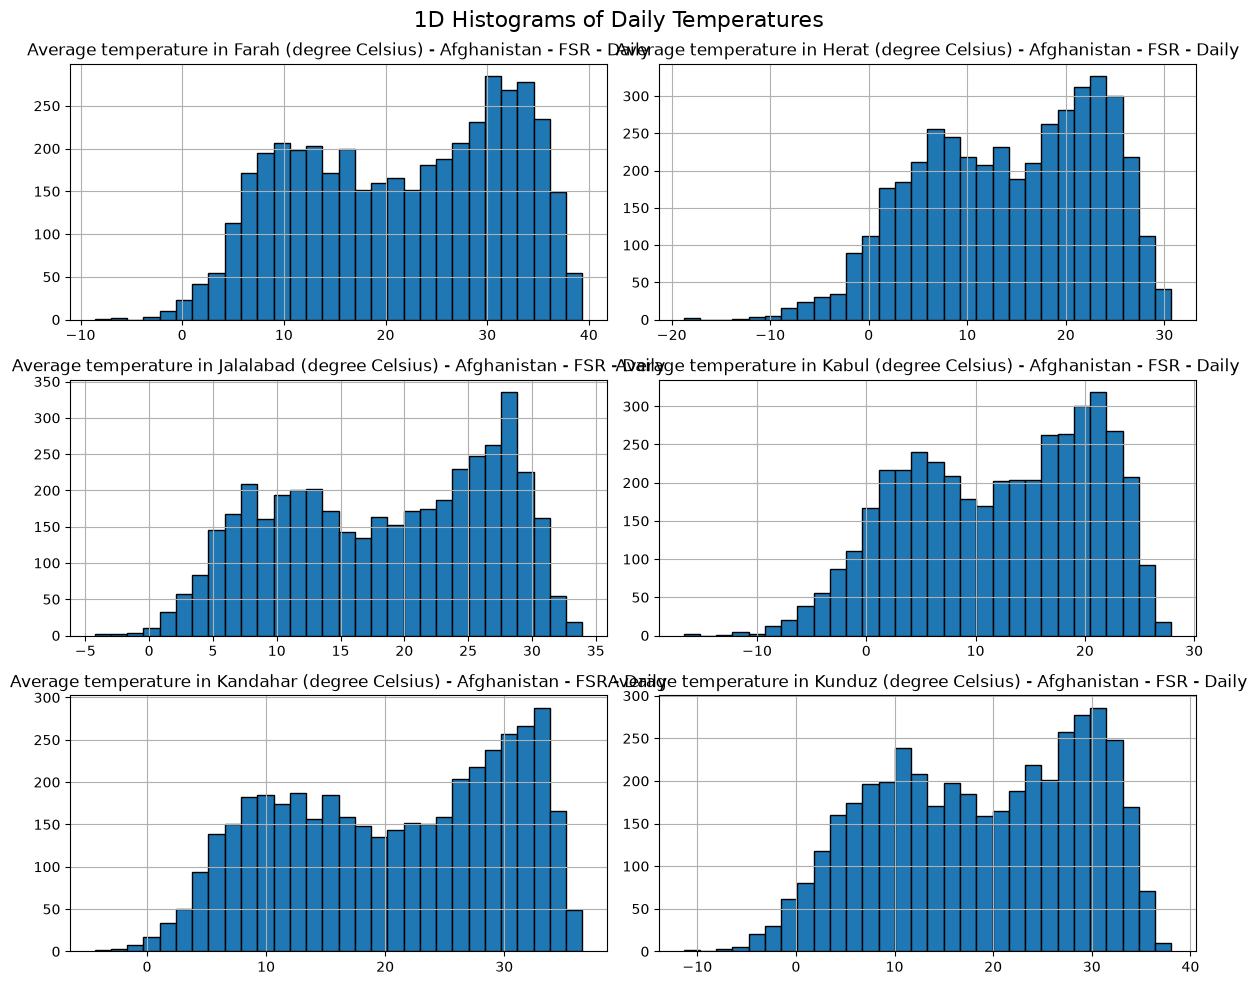

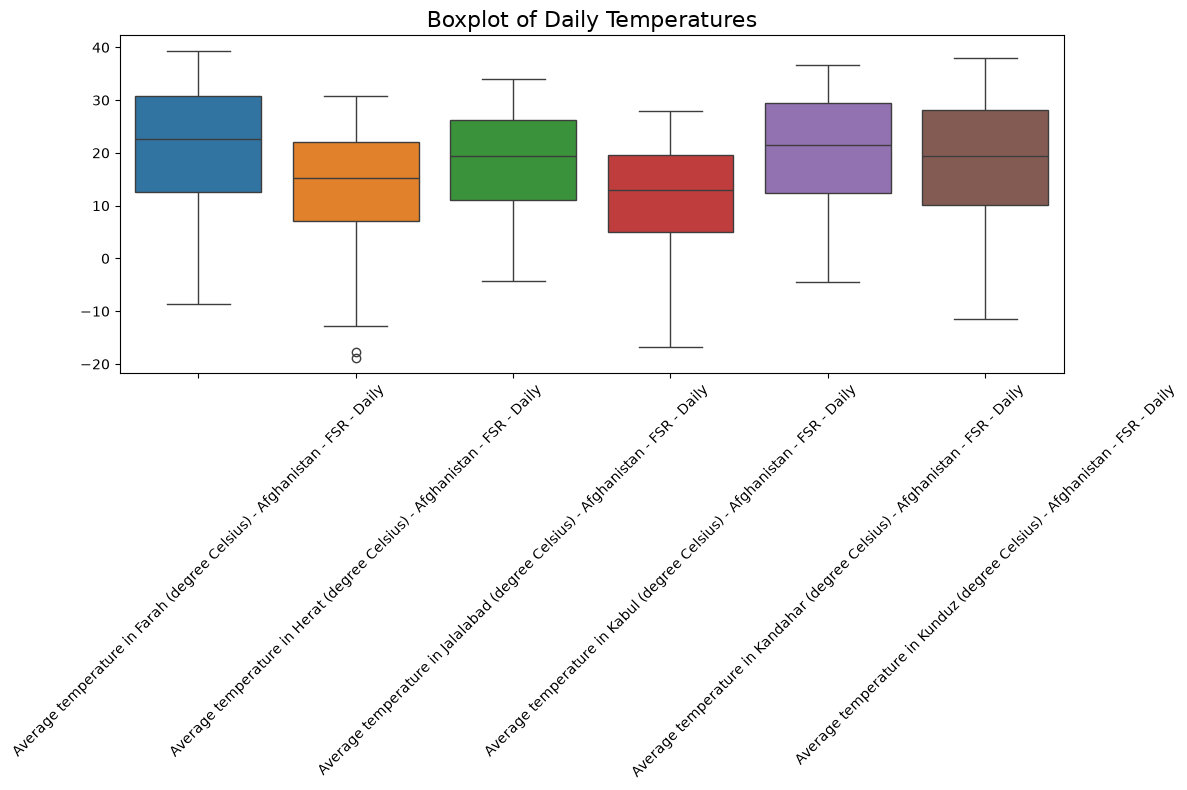

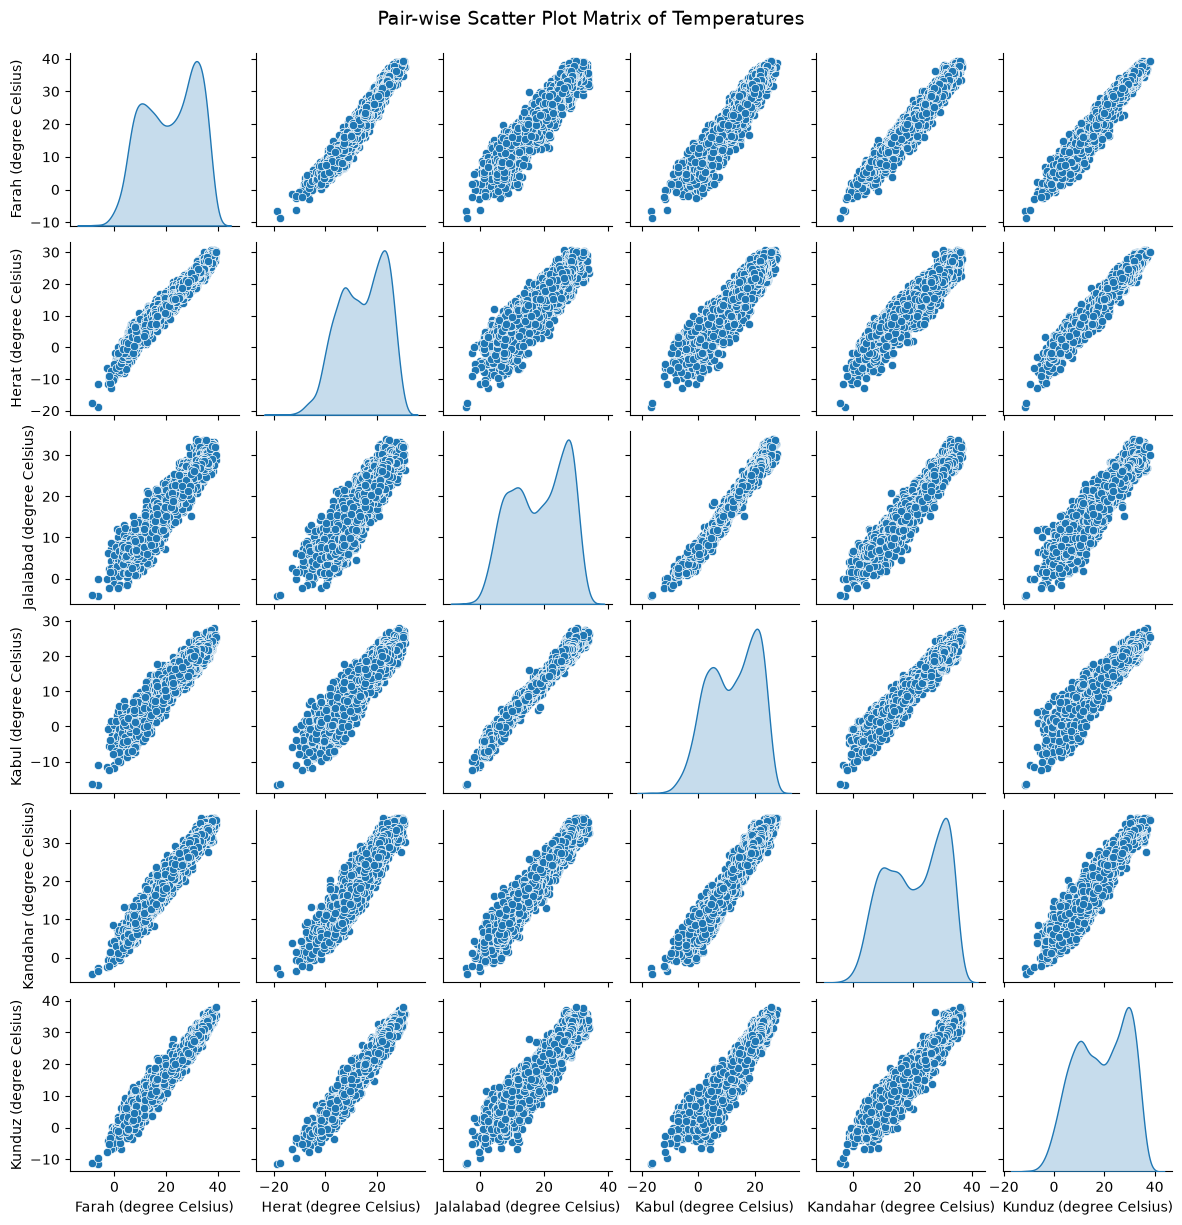

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

df = pd.read_csv("Average temperture in Stockholm - Average temperatures.csv")

# Verify the data loaded successfully
print(df.shape)
df.head()

#choose the columns to plot
selected_cols = [
    'Average temperature in Farah (degree Celsius) - Afghanistan - FSR - Daily',
    'Average temperature in Herat (degree Celsius) - Afghanistan - FSR - Daily',
    'Average temperature in Jalalabad (degree Celsius) - Afghanistan - FSR - Daily',
    'Average temperature in Kabul (degree Celsius) - Afghanistan - FSR - Daily',
    'Average temperature in Kandahar (degree Celsius) - Afghanistan - FSR - Daily',
    'Average temperature in Kunduz (degree Celsius) - Afghanistan - FSR - Daily'
]

# Ensure the selected columns are treated as numbers
for col in selected_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')

#Calculate and print statistics for the selected columns
stats = pd.DataFrame({
    'Mean': df[selected_cols].mean(),
    'Median': df[selected_cols].median(),
    'Standard Deviation': df[selected_cols].std(),
    'Minimum': df[selected_cols].min(),
    'Maximum': df[selected_cols].max()
})
#Print the statistics
print(stats)
print("\n")

#Plotting the data 1D Histogram for each variable
df[selected_cols].hist(bins=30, figsize=(12, 10), edgecolor='black')
plt.suptitle('1D Histograms of Daily Temperatures', fontsize=16)
plt.tight_layout()
plt.show()

#Make a boxplot putting all the variables together
plt.figure(figsize=(12, 8))
sns.boxplot(data=df[selected_cols])
plt.title('Boxplot of Daily Temperatures', fontsize=16)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Create a temporary dataframe with clean, short column names for the plot
plot_df = df[selected_cols].rename(
    columns={col: col.split(' - ')[0].replace('Average temperature in ', '') for col in selected_cols}
)

#Make a matrix of scatterplots to show pair_wise relationships between the variables
# Generate the pairplot with the clean names
sns.pairplot(plot_df, diag_kind='kde', height=2.0)
plt.suptitle('Pair-wise Scatter Plot Matrix of Temperatures', y=1.02, fontsize=14)
plt.show()

#Answer questions 
# To show the relationship between two categorical variables, I’d use a grouped or stacked bar chart, or make a 
# crosstab table using pd.crosstab() and plot it as a heatmap to see how the counts or percentages line up across categories
# 2. For categorical vs. numerical data using color, I’d make a scatter plot, box plot, and set the hue
#  parameter in Seaborn to the categorical variable. That way, each category gets its own distinct color so you can
#  easily compare the numerical distributions.